# Card Fraud Early Warning

**The question a fraud team actually asks:** with a fixed number of analysts, which transactions should we review today, and how quickly do we stop a stolen card?

**Data:** 1.85M card transactions over two years (2019–2020), 999 cards, 9,651 frauds (0.52%). Synthetic, generated with the Sparkov simulator (Kaggle "Credit Card Transactions Fraud Detection", CC0), with real-shaped fields: timestamp, amount, merchant, category, card, cardholder and merchant location. Unlike the usual Kaggle fraud dataset, nothing is anonymised, so behavioural features can be built.

**Why this dataset and not the first one I tried:** a different, larger Sparkov dataset (2.6M transactions, 2021–2023) failed the data audit below. Its normal transactions had broken timestamps: whole categories only appeared in certain half-years, and in 2023 no normal purchase happened before noon. A model scored 0.93 PR-AUC on it by learning those quirks. See the README.

**Pipeline:**
1. `src/download_data.py`: download, drop PII-like fields, hash card numbers.
2. `sql/features.sql` (DuckDB): per-card behaviour features using only *earlier* transactions. `tests/` proves no future data leaks in.
3. This notebook: **data audit** → time-based split → before/after test of behavioural features → evaluation under an analyst budget → time-to-detection per stolen card → monitoring → SHAP reason codes.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from src.reason_codes import top_reasons

SEED = 42
FIG, OUT = ROOT / "figures", ROOT / "outputs"
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C_STATIC, C_BEHAV, C_GREY = "#9aa5b1", "#d1495b", "#52606d"
con = duckdb.connect()
con.execute(f"CREATE VIEW features AS SELECT * FROM read_parquet('{ROOT / 'data/features.parquet'}')")
sql = lambda q: con.sql(q).df()

## 1. Data audit before any modelling

Synthetic data has quirks, and a model will happily learn them. Four checks, written in SQL. (These are the checks that rejected the first dataset.)

### Check 1: is the time-of-day pattern stable across years?

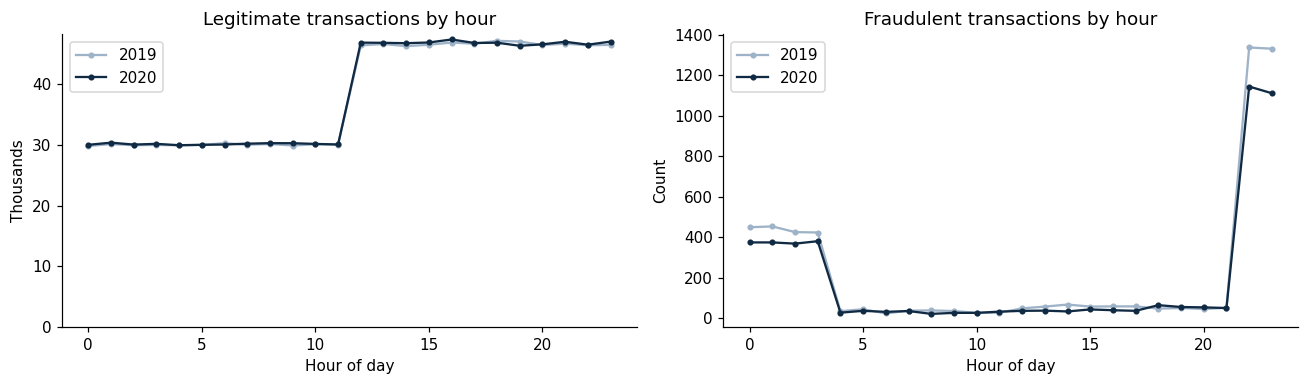

In [2]:
hours = sql("""
    SELECT year(ts) AS year, hour, is_fraud, count(*) AS n
    FROM features GROUP BY ALL
""")
legit = hours[hours.is_fraud == 0].pivot(index="hour", columns="year", values="n").fillna(0)
fraud = hours[hours.is_fraud == 1].pivot(index="hour", columns="year", values="n").fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for yr, col in zip(legit.columns, ["#9fb3c8", "#102a43"]):
    axes[0].plot(legit.index, legit[yr] / 1000, "o-", ms=3, color=col, label=yr)
    axes[1].plot(fraud.index, fraud[yr], "o-", ms=3, color=col, label=yr)
axes[0].set(title="Legitimate transactions by hour", xlabel="Hour of day", ylabel="Thousands", ylim=(0, None))
axes[1].set(title="Fraudulent transactions by hour", xlabel="Hour of day", ylabel="Count")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "audit_hours.png", bbox_inches="tight"); plt.show()

**Passes.** Both years look the same. Fraud clusters between 22:00 and 03:59, which is a rule built into the simulator. Time of day will be a strong feature here; real fraud is less tidy, so treat that part of the result with caution.

### Check 2: does every category have normal transactions in every period?

In [3]:
sql("""
    PIVOT (
        SELECT category, year(ts) || '-H' || CASE WHEN month(ts) <= 6 THEN 1 ELSE 2 END AS period,
               count(*) FILTER (WHERE is_fraud = 0) AS legit
        FROM features GROUP BY ALL
    ) ON period USING first(legit) ORDER BY category
""")

,category,2019-H1,2019-H2,2020-H1,2020-H2
0,entertainment,28831,38103,29027,37865
1,food_dining,28297,37060,28191,36976
2,gas_transport,40359,53061,40412,53425
3,grocery_net,13898,18328,14103,18374
4,grocery_pos,37721,48970,37822,49450
5,health_fitness,26601,34418,26768,34581
6,home,37856,49864,38079,49396
7,kids_pets,34681,45791,35104,45847
8,misc_net,19181,25230,19328,25733
9,misc_pos,24268,32441,24536,32662


**Passes.** Every category has normal spending in every half-year, in similar amounts. (The rejected dataset failed exactly this check: all its normal "travel" spending sat in one half-year.)

### Check 3: does every card have normal history?

In [4]:
sql("""
    WITH cards AS (
        SELECT card_id, sum(1 - is_fraud) AS legit_txns, sum(is_fraud) AS fraud_txns
        FROM features GROUP BY card_id
    )
    SELECT legit_txns = 0 AS fraud_only_card, count(*) AS cards, sum(fraud_txns) AS frauds
    FROM cards GROUP BY 1 ORDER BY 1
""")

,fraud_only_card,cards,frauds
0,False,908,8747.0
1,True,91,904.0


**Fails.** 91 cards have only fraudulent transactions and no normal history at all. For these, "card never seen before" means fraud 100% of the time. Real new cards do get defrauded, but not every single time.

**Decision:** exclude these 91 cards (904 frauds, about 9%). Results below are for established cards, which is where behavioural features apply.

### Check 4: is normal spending stable over time?

In [5]:
sql("""
    SELECT year(ts) AS year,
           round(median(amt) FILTER (WHERE is_fraud = 0), 2) AS legit_median_amt,
           round(median(amt) FILTER (WHERE is_fraud = 1), 2) AS fraud_median_amt,
           count(*) FILTER (WHERE is_fraud = 1)              AS frauds,
           round(avg(is_fraud) * 100, 3)                     AS fraud_rate_pct
    FROM features GROUP BY 1 ORDER BY 1
""")

,year,legit_median_amt,fraud_median_amt,frauds,fraud_rate_pct
0,2019,47.18,390.88,5220,0.564
1,2020,47.30,387.41,4431,0.478


**Passes.** Amounts are stable; the fraud rate is a bit lower in 2020.

**Two more exclusions, found by reasoning rather than charts:**
- **Cardholder profile fields** (age, gender, city population): with only ~900 cards, the combination is close to a unique fingerprint. Nearly every card is defrauded once, so a model could learn "this card was hit in training", which is useless going forward.
- **`card_tenure_days`**: almost every card starts in January 2019, so tenure is really just the calendar date in disguise.

In [6]:
df = sql("""
    SELECT * FROM features
    WHERE card_id IN (SELECT card_id FROM features GROUP BY card_id HAVING sum(1 - is_fraud) > 0)
    ORDER BY ts, txn_id
""")
df = pd.get_dummies(df, columns=["category"], prefix="cat", dtype=int).assign(category=df["category"])
df["date"] = df.ts.dt.normalize()
print(f"Modelling set: {len(df):,} transactions | {df.card_id.nunique()} cards | {df.is_fraud.sum():,} frauds ({df.is_fraud.mean():.2%})")

Modelling set: 1,851,490 transactions | 908 cards | 8,747 frauds (0.47%)


### How fraud shows up

Fraud comes in **episodes**: a card is compromised and used several times over a couple of days. Catching the first fraudulent transaction and blocking the card is worth far more than catching the tenth, which shapes the evaluation later.

Fraud episodes: 885 | median 10 transactions over 45 hours, $5,147 stolen


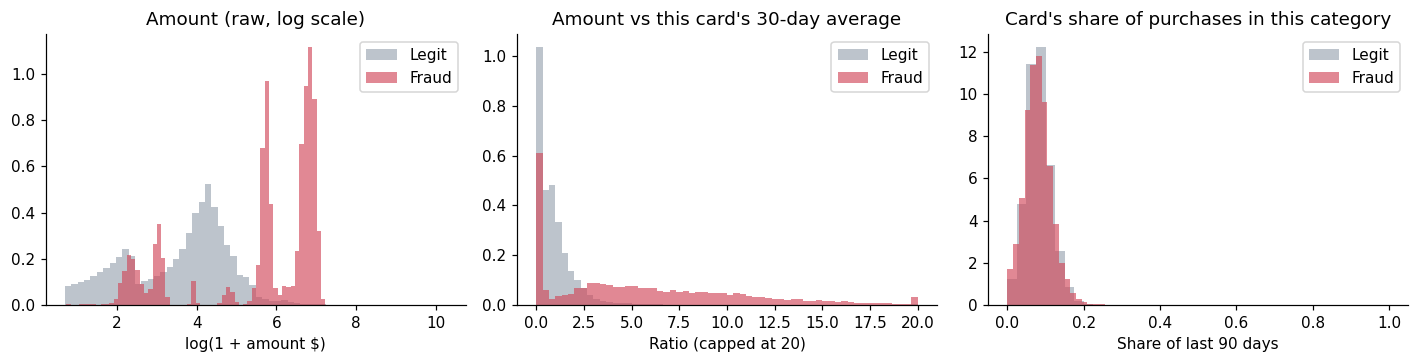

In [7]:
fr = df[df.is_fraud == 1].sort_values("ts")
ep = fr.groupby("card_id").agg(n_txn=("amt", "size"), total=("amt", "sum"), start=("ts", "min"), end=("ts", "max"))
ep["hours"] = (ep.end - ep.start).dt.total_seconds() / 3600
print(f"Fraud episodes: {len(ep)} | median {ep.n_txn.median():.0f} transactions over {ep.hours.median():.0f} hours, ${ep.total.median():,.0f} stolen")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for c, col, lab in [(0, C_STATIC, "Legit"), (1, C_BEHAV, "Fraud")]:
    d = df[df.is_fraud == c]
    axes[0].hist(d.log_amt, bins=60, density=True, alpha=.65, color=col, label=lab)
    axes[1].hist(d.amt_vs_30d_avg.clip(0, 20), bins=60, density=True, alpha=.65, color=col, label=lab)
    axes[2].hist(d.category_share_90d, bins=40, density=True, alpha=.65, color=col, label=lab)
axes[0].set(title="Amount (raw, log scale)", xlabel="log(1 + amount $)")
axes[1].set(title="Amount vs this card's 30-day average", xlabel="Ratio (capped at 20)")
axes[2].set(title="Card's share of purchases in this category", xlabel="Share of last 90 days")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig(FIG / "eda.png", bbox_inches="tight"); plt.show()

The raw amount overlaps a lot between legit and fraud. Amount *relative to what this card normally spends*, and how unusual the category is *for this card*, separate them much better. That is the case for behavioural features.

## 2. Time-based split

| Set | Period | Used for |
|---|---|---|
| Train | Jan 2019 – Mar 2020 | fitting models |
| Validation | Apr – Jun 2020 | model choice, early stopping, setting the alert threshold |
| Test | Jul – Dec 2020 | final numbers, touched once |

In [8]:
train = df[df.ts < "2020-04-01"]
val = df[(df.ts >= "2020-04-01") & (df.ts < "2020-07-01")]
test = df[df.ts >= "2020-07-01"]
pd.DataFrame({s: {"rows": len(d), "frauds": int(d.is_fraud.sum()), "fraud rate": f"{d.is_fraud.mean():.3%}",
                  "txns/day": round(len(d) / d.date.nunique()), "frauds/day": round(d.is_fraud.sum() / d.date.nunique(), 1)}
              for s, d in [("train", train), ("validation", val), ("test", test)]}).T

,rows,frauds,fraud rate,txns/day,frauds/day
train,1097089,5739,0.523%,2411,12.6
validation,228891,1147,0.501%,2515,12.6
test,525510,1861,0.354%,2856,10.1


## 3. Features: static vs behavioural

- **Static** = what you know from the transaction alone: amount, category, hour, day of week, distance from the cardholder's home to the merchant.
- **Behavioural** = static + what this card has been doing: transaction counts in the last 1h / 24h / 7d, amount spent in the last 24h, night-time activity in the last 24h, amount vs the card's 30-day average and 90-day spread, how much of the card's recent activity is at night or in this category, first time in this category or at this merchant, time since the previous transaction.

All behavioural features come from `sql/features.sql` and use only the card's earlier transactions.

In [9]:
CAT = [c for c in df.columns if c.startswith("cat_")]
STATIC = ["log_amt", "hour", "day_of_week", "is_night", "distance_km"] + CAT
BEHAV = STATIC + ["n_txn_1h", "n_txn_24h", "n_txn_7d", "amt_sum_24h", "n_night_24h", "card_avg_amt_30d",
                  "amt_vs_30d_avg", "amt_zscore_90d", "night_share_90d", "category_share_90d",
                  "first_time_category", "first_time_merchant", "hours_since_prev"]
print(f"Static: {len(STATIC)} features | Behavioural: {len(BEHAV)} features")

Static: 19 features | Behavioural: 32 features


## 4. Models

XGBoost throughout, with early stopping on validation PR-AUC.

**Class imbalance (about 0.5% fraud).** v1 of this project compared SMOTE, undersampling and class weights and found resampling did not help. SMOTE is also a bad fit here on principle: it creates new points by blending two real transactions, which would invent impossible card histories. So the comparison is simply with and without `scale_pos_weight` (class weights).

In [10]:
spw = (train.is_fraud == 0).sum() / train.is_fraud.sum()

def fit_xgb(features, weight):
    m = xgb.XGBClassifier(n_estimators=600, max_depth=5, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=5, scale_pos_weight=weight, eval_metric="aucpr",
                          early_stopping_rounds=30, tree_method="hist", n_jobs=-1, random_state=SEED)
    m.fit(train[features], train.is_fraud, eval_set=[(val[features], val.is_fraud)], verbose=False)
    return m

specs = {
    "static, class weights": (STATIC, spw),
    "behavioural, no weights": (BEHAV, 1.0),
    "behavioural, class weights": (BEHAV, spw),
}
fitted, rows = {}, []
for name, (feats, w) in specs.items():
    m = fit_xgb(feats, w)
    pv = m.predict_proba(val[feats])[:, 1]
    fitted[name] = (m, feats)
    rows.append({"model": name, "val PR_AUC": average_precision_score(val.is_fraud, pv),
                 "val ROC_AUC": roc_auc_score(val.is_fraud, pv), "trees": m.best_iteration + 1})
val_results = pd.DataFrame(rows).round(3)
val_results

,model,val PR_AUC,val ROC_AUC,trees
0,"static, class weights",0.800,0.997,303
1,"behavioural, no weights",0.975,0.999,508
2,"behavioural, class weights",0.979,0.999,513


- **Static features already do reasonably well** (PR-AUC about 0.8), because the simulator's fraud is mostly large purchases at night in a few categories.
- **Behavioural features close most of the remaining gap** (about 0.98). The next sections show what that means in missed fraud and analyst time.
- **Class weights make almost no difference**, which matches v1: the imbalance is better handled at the threshold.

### Is XGBoost worth its complexity? A simple baseline

Logistic regression on the same behavioural features. Skewed features (amount ratios, counts) are mapped to a normal shape first, so the linear model gets a fair chance. If it came close, it would be the better choice: easier to explain, audit and run.

In [11]:
logreg = make_pipeline(SimpleImputer(strategy="median"), QuantileTransformer(output_distribution="normal", random_state=SEED),
                       LogisticRegression(max_iter=2000, class_weight="balanced"))
logreg.fit(train[BEHAV], train.is_fraud)
p_val_lr = logreg.predict_proba(val[BEHAV])[:, 1]
val_results = pd.concat([val_results, pd.DataFrame([{
    "model": "logistic regression, behavioural", "val PR_AUC": round(average_precision_score(val.is_fraud, p_val_lr), 3),
    "val ROC_AUC": round(roc_auc_score(val.is_fraud, p_val_lr), 3), "trees": np.nan}])], ignore_index=True)
val_results

,model,val PR_AUC,val ROC_AUC,trees
0,"static, class weights",0.800,0.997,303.0
1,"behavioural, no weights",0.975,0.999,508.0
2,"behavioural, class weights",0.979,0.999,513.0
3,"logistic regression, behavioural",0.667,0.984,NaN


**XGBoost earns its place here:** 0.98 vs 0.67 PR-AUC. The signal lives in combinations (a large amount *and* late at night *and* a burst of activity), which a linear model can't express without hand-built interaction terms.

### Which feature groups carry the signal?

Drop one group at a time from the behavioural model and measure the loss in validation PR-AUC. This is more trustworthy than a feature-importance chart, because correlated features can share or steal credit in importance scores but can't hide from being removed.

In [12]:
GROUPS = {
    "velocity (counts, $ in last 1h/24h/7d)": ["n_txn_1h", "n_txn_24h", "n_txn_7d", "amt_sum_24h"],
    "night behaviour (card's night activity)": ["n_night_24h", "night_share_90d"],
    "card's normal spend (ratios, z-score)": ["card_avg_amt_30d", "amt_vs_30d_avg", "amt_zscore_90d"],
    "novelty (new category / merchant)": ["category_share_90d", "first_time_category", "first_time_merchant"],
    "timing (hours since previous txn)": ["hours_since_prev"],
}
base_ap = average_precision_score(val.is_fraud, fitted["behavioural, class weights"][0].predict_proba(val[BEHAV])[:, 1])
abl = []
for g, cols in GROUPS.items():
    feats = [f for f in BEHAV if f not in cols]
    m = fit_xgb(feats, spw)
    ap_g = average_precision_score(val.is_fraud, m.predict_proba(val[feats])[:, 1])
    abl.append({"feature group removed": g, "val PR_AUC": ap_g, "drop vs full model": base_ap - ap_g})
ablation = pd.DataFrame(abl).sort_values("drop vs full model", ascending=False).round(4)
ablation

,feature group removed,val PR_AUC,drop vs full model
0,"velocity (counts, $ in last 1h/24h/7d)",0.9449,0.0346
1,night behaviour (card's night activity),0.9715,0.0080
2,"card's normal spend (ratios, z-score)",0.9743,0.0052
3,novelty (new category / merchant),0.9779,0.0016
4,timing (hours since previous txn),0.9782,0.0012


**Velocity is the group the model can't do without** (PR-AUC drops from 0.979 to 0.945 without it). Every other group costs under 0.01 when removed, not because it's useless, but because the groups overlap: a burst of spending at night shows up in velocity, night activity and the amount ratios at the same time. If I had to ship a smaller model, velocity is what I'd keep.

In [13]:
model_b, feats_b = fitted["behavioural, class weights"]
model_s, feats_s = fitted["static, class weights"]

## 5. Threshold by analyst capacity

A fraud team does not pick a threshold, it has a **review budget**. Assume **15 alerts a day**: about 1.5x the daily fraud count, well under 1% of daily transactions. On validation data, pick the score that would have produced 15 alerts a day, then apply it to the test period.

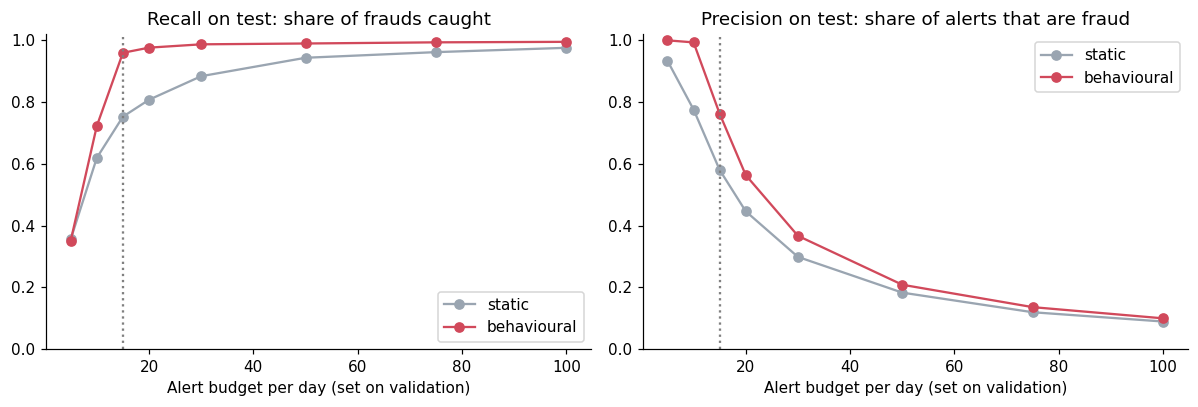

recall          precision        actual alerts/day         
features   behavioural static behavioural static       behavioural   static
budget/day                                                                 
5                0.351  0.356       1.000  0.934             3.554    3.859
10               0.723  0.620       0.993  0.776             7.359    8.076
15               0.960  0.753       0.762  0.580            12.734   13.120
20               0.976  0.808       0.564  0.446            17.522   18.299
30               0.987  0.884       0.367  0.299            27.201   29.918
50               0.990  0.944       0.209  0.183            47.973   52.114
75               0.994  0.962       0.136  0.120            73.810   81.326
100              0.995  0.976       0.100  0.090           100.777  110.207

In [14]:
BUDGET = 15
days_val, days_te = val.date.nunique(), test.date.nunique()

def threshold_for_budget(scores, n_days, per_day):
    return np.sort(scores)[::-1][int(per_day * n_days) - 1]

p_val_b, p_val_s = model_b.predict_proba(val[feats_b])[:, 1], model_s.predict_proba(val[feats_s])[:, 1]
p_te_b, p_te_s = model_b.predict_proba(test[feats_b])[:, 1], model_s.predict_proba(test[feats_s])[:, 1]
y_te, amt_te = test.is_fraud.values, test.amt.values
t_b, t_s = threshold_for_budget(p_val_b, days_val, BUDGET), threshold_for_budget(p_val_s, days_val, BUDGET)

curve = []
for b in [5, 10, 15, 20, 30, 50, 75, 100]:
    for name, pv, pt in [("static", p_val_s, p_te_s), ("behavioural", p_val_b, p_te_b)]:
        flag = pt >= threshold_for_budget(pv, days_val, b)
        curve.append({"budget/day": b, "features": name, "actual alerts/day": flag.sum() / days_te,
                      "recall": recall_score(y_te, flag), "precision": precision_score(y_te, flag, zero_division=0)})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, col in [("static", C_STATIC), ("behavioural", C_BEHAV)]:
    c = curve[curve.features == name]
    axes[0].plot(c["budget/day"], c.recall, "o-", color=col, label=name)
    axes[1].plot(c["budget/day"], c.precision, "o-", color=col, label=name)
for ax, t in zip(axes, ["Recall on test: share of frauds caught", "Precision on test: share of alerts that are fraud"]):
    ax.axvline(BUDGET, ls=":", c="grey"); ax.set(xlabel="Alert budget per day (set on validation)", title=t, ylim=(0, 1.02)); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "budget_curve.png", bbox_inches="tight"); plt.show()
curve.pivot(index="budget/day", columns="features", values=["recall", "precision", "actual alerts/day"]).round(3)

## 6. Test results at a budget of 15 alerts/day

Confidence intervals use a **card-level bootstrap**: resample whole cards, not single transactions. Frauds in one episode are strongly linked, so treating them as independent would make the intervals falsely narrow.

In [15]:
flag_b, flag_s = p_te_b >= t_b, p_te_s >= t_s

def summary(flag, p):
    return {"alerts/day": flag.sum() / days_te, "precision": precision_score(y_te, flag), "recall": recall_score(y_te, flag),
            "PR_AUC": average_precision_score(y_te, p), "frauds caught": int((flag & (y_te == 1)).sum()),
            "false alarms": int((flag & (y_te == 0)).sum()), "frauds missed": int((~flag & (y_te == 1)).sum()),
            "fraud $ caught": amt_te[flag & (y_te == 1)].sum(), "fraud $ missed": amt_te[~flag & (y_te == 1)].sum()}

test_table = pd.DataFrame({"static": summary(flag_s, p_te_s), "behavioural": summary(flag_b, p_te_b)})
print(f"Test period: {days_te} days, {y_te.sum():,} frauds, ${amt_te[y_te == 1].sum():,.0f} fraud value")
test_table.round(3)

Test period: 184 days, 1,861 frauds, $958,614 fraud value


,static,behavioural
alerts/day,13.120,12.734
precision,0.580,0.762
recall,0.753,0.960
PR_AUC,0.744,0.967
frauds caught,1401.000,1786.000
false alarms,1013.000,557.000
frauds missed,460.000,75.000
fraud $ caught,844200.000,939695.410
fraud $ missed,114413.750,18918.340


In [16]:
rng = np.random.default_rng(SEED)
per_card = pd.DataFrame({"card": test.card_id.values, "tp_b": flag_b & (y_te == 1), "fp_b": flag_b & (y_te == 0),
                         "tp_s": flag_s & (y_te == 1), "fp_s": flag_s & (y_te == 0), "pos": y_te == 1}).groupby("card").sum()
boot = []
for _ in range(2000):
    s = per_card.iloc[rng.integers(0, len(per_card), len(per_card))].sum()
    boot.append({"precision (behavioural)": s.tp_b / (s.tp_b + s.fp_b), "recall (behavioural)": s.tp_b / s.pos,
                 "precision (static)": s.tp_s / max(s.tp_s + s.fp_s, 1), "recall (static)": s.tp_s / s.pos,
                 "recall gain": (s.tp_b - s.tp_s) / s.pos})
boot = pd.DataFrame(boot)
point = {"precision (behavioural)": precision_score(y_te, flag_b), "recall (behavioural)": recall_score(y_te, flag_b),
         "precision (static)": precision_score(y_te, flag_s), "recall (static)": recall_score(y_te, flag_s),
         "recall gain": recall_score(y_te, flag_b) - recall_score(y_te, flag_s)}
ci = pd.DataFrame({"point": point, "CI_low": boot.quantile(.025), "CI_high": boot.quantile(.975)})
ci.round(3)

,point,CI_low,CI_high
precision (behavioural),0.762,0.732,0.790
recall (behavioural),0.960,0.949,0.970
precision (static),0.580,0.539,0.617
recall (static),0.753,0.724,0.779
recall gain,0.207,0.181,0.234


## 6b. Can the scores be read as probabilities?

Class weights tell the model fraud is ~200x more important than it is, so raw scores are inflated. That doesn't hurt ranking, but anyone reading "0.8" as "80% chance of fraud" is misled, and any $-based decision needs real probabilities.

Fix: fit an **isotonic calibration** on the validation period (a monotonic mapping from score to observed fraud rate), then check it on test.

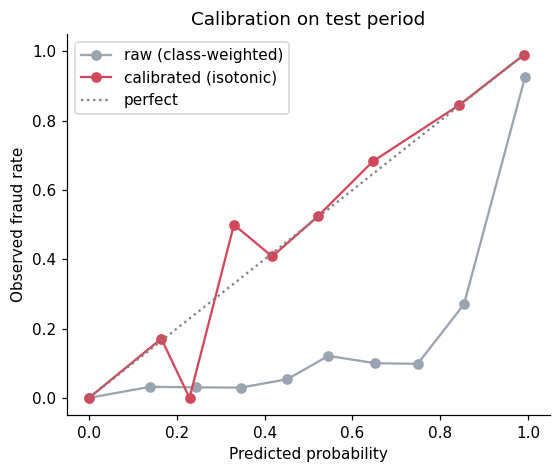

,raw scores,calibrated
Brier score (lower = better),0.0009,0.0004
mean predicted,0.0051,0.0035
actual fraud rate,0.0035,0.0035
PR_AUC,0.9667,0.9624


In [17]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val_b, val.is_fraud)
p_te_cal = iso.predict(p_te_b)

cal_table = pd.DataFrame({
    "raw scores": {"Brier score (lower = better)": brier_score_loss(y_te, p_te_b), "mean predicted": p_te_b.mean(),
                   "actual fraud rate": y_te.mean(), "PR_AUC": average_precision_score(y_te, p_te_b)},
    "calibrated": {"Brier score (lower = better)": brier_score_loss(y_te, p_te_cal), "mean predicted": p_te_cal.mean(),
                   "actual fraud rate": y_te.mean(), "PR_AUC": average_precision_score(y_te, p_te_cal)},
})

fig, ax = plt.subplots(figsize=(5.2, 4.4))
for p, lab, col in [(p_te_b, "raw (class-weighted)", C_STATIC), (p_te_cal, "calibrated (isotonic)", C_BEHAV)]:
    frac, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="uniform")
    ax.plot(mean_pred, frac, "o-", color=col, label=lab)
ax.plot([0, 1], [0, 1], ls=":", c="grey", label="perfect")
ax.set(xlabel="Predicted probability", ylabel="Observed fraud rate", title="Calibration on test period")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "calibration.png", bbox_inches="tight"); plt.show()
cal_table.round(4)

Raw scores overstate risk badly in the middle: transactions scored around 0.75 turn out to be fraud only about 10% of the time. After calibration, predicted and observed rates line up (the middle bins are noisy because few transactions land there), the average predicted rate matches the real fraud rate, and the Brier score halves. Ranking quality barely moves (PR-AUC 0.967 → 0.962; isotonic calibration creates a few ties).

### Rank by expected loss, not by probability

With real probabilities, each transaction has an **expected fraud loss = probability x amount**. A $1,500 transaction at 40% risk costs more in expectation than a $15 one at 90%. Same budget, same model; only the ranking changes. Thresholds for both rankings are set on validation.

In [18]:
el_val = iso.predict(p_val_b) * val.amt.values
el_te = p_te_cal * amt_te
t_el = threshold_for_budget(el_val, days_val, BUDGET)
flag_el = el_te >= t_el
rank_cmp = pd.DataFrame({"rank by probability": summary(flag_b, p_te_b), "rank by expected $ loss": summary(flag_el, el_te)}).drop("PR_AUC")
rank_cmp.round(3)

,rank by probability,rank by expected $ loss
alerts/day,12.734,12.886
precision,0.762,0.660
recall,0.960,0.841
frauds caught,1786.000,1565.000
false alarms,557.000,806.000
frauds missed,75.000,296.000
fraud $ caught,939695.410,947721.110
fraud $ missed,18918.340,10892.640


**A real trade-off, not a free win.** Ranking by expected loss cuts missed fraud *value* by about 40% ($18.9k → $10.9k), but misses four times as many fraud *transactions* (75 → 296) and precision drops from 0.76 to 0.66. It gives up small frauds to catch big ones.

Which is right is a business decision, not a modelling one. Small frauds are often card testing, a thief checking the card works before a big purchase. Letting them through means the big one comes next, and each one is a customer who has to call in. So I would keep probability ranking as the default, and bring expected-loss ranking to the fraud team as an option with these numbers attached.

## 6c. What does the model miss?

In [19]:
missed = test[(y_te == 1) & ~flag_b]
caught = test[(y_te == 1) & flag_b]
first_in_ep = test[y_te == 1].groupby("card_id").ts.transform("min") == test.loc[y_te == 1, "ts"]
test_fraud_first = pd.Series(False, index=test.index); test_fraud_first.loc[first_in_ep.index] = first_in_ep.values
err = pd.DataFrame({
    "caught frauds": [len(caught), caught.amt.median(), caught.is_night.mean(), caught.amt_vs_30d_avg.median(),
                      caught.n_txn_24h.median(), test_fraud_first.loc[caught.index].mean()],
    "missed frauds": [len(missed), missed.amt.median(), missed.is_night.mean(), missed.amt_vs_30d_avg.median(),
                      missed.n_txn_24h.median(), test_fraud_first.loc[missed.index].mean()],
}, index=["count", "median amount $", "share at night", "median amount vs 30d avg", "median txns in past 24h",
          "share that are first fraud of episode"]).round(2)
err

,caught frauds,missed frauds
count,1786.00,75.00
median amount $,364.28,51.43
share at night,0.85,0.55
median amount vs 30d avg,5.01,0.86
median txns in past 24h,4.00,2.00
share that are first fraud of episode,0.09,0.33


In [20]:
print(f"Missed frauds: {len(missed)} worth ${missed.amt.sum():,.0f} "
      f"({missed.amt.sum() / amt_te[y_te == 1].sum():.1%} of test fraud value)")
print("Amount bands of missed frauds:")
print(pd.cut(missed.amt, [0, 20, 100, 300, 1000, 1e6], labels=["<$20", "$20-100", "$100-300", "$300-1k", ">$1k"]).value_counts().sort_index().to_string())

Missed frauds: 75 worth $18,918 (2.0% of test fraud value)
Amount bands of missed frauds:
amt
<$20        21
$20-100     21
$100-300    16
$300-1k     13
>$1k         4


**The missed frauds look like normal spending:** median $51 (vs $364 for caught frauds), at the card's usual amount (0.86x its 30-day average), only 55% at night, and a third of them are the *first* fraudulent transaction of an episode, before any burst has built up. That's the classic card-testing pattern. The features that would catch it (device, card-present flag, many small transactions across merchants in minutes) aren't in this data. They're the first thing I'd ask for on a real project.

## 7. How fast is a stolen card stopped?

Transaction-level recall treats every fraud the same. In practice the **first alert on an episode** is what counts: the card gets blocked and the rest of the episode is prevented. For every fraud episode that starts in the test period:

- **Detected:** at least one of its fraudulent transactions was alerted.
- **Fraud transactions before the first alert**, and the **$ lost** before it.
- **$ saved** if the card is blocked at the first alert.

This assumes the alert is reviewed and the card blocked before the next transaction. That is optimistic; treat "$ saved" as an upper bound.

In [21]:
starts = df[df.is_fraud == 1].groupby("card_id").ts.min()
t_fraud = test.assign(flag_b=flag_b, flag_s=flag_s)[y_te == 1]
t_fraud = t_fraud[t_fraud.card_id.map(starts) >= "2020-07-01"].sort_values("ts")

def episode_stats(flag_col):
    out = []
    for _, g in t_fraud.groupby("card_id"):
        hit = np.flatnonzero(g[flag_col].values)
        first = hit[0] if len(hit) else len(g)
        out.append({"detected": len(hit) > 0, "txns_before_alert": first, "lost": g.amt.values[:first].sum(),
                    "total": g.amt.sum(),
                    "hours_to_alert": (g.ts.values[first] - g.ts.values[0]) / np.timedelta64(1, "h") if len(hit) else np.nan})
    return pd.DataFrame(out)

eps = {"static": episode_stats("flag_s"), "behavioural": episode_stats("flag_b")}
ep_table = pd.DataFrame({k: {"episodes": len(e), "detected": f"{e.detected.mean():.1%}",
                             "caught on 1st fraud txn": f"{(e.txns_before_alert == 0).mean():.1%}",
                             "mean fraud txns before first alert": round(e.txns_before_alert.mean(), 2),
                             "$ lost before first alert": round(e.lost.sum()),
                             "$ saved if blocked at first alert": round(e.total.sum() - e.lost.sum()),
                             "share of episode $ saved": f"{1 - e.lost.sum() / e.total.sum():.1%}"}
                         for k, e in eps.items()})
ep_table

,static,behavioural
episodes,188,188
detected,97.9%,100.0%
caught on 1st fraud txn,81.9%,86.7%
mean fraud txns before first alert,0.29,0.17
$ lost before first alert,16288,7444
$ saved if blocked at first alert,941091,949935
share of episode $ saved,98.3%,99.2%


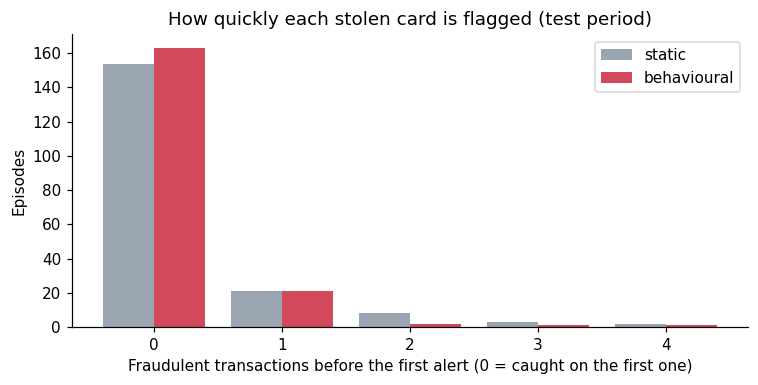

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.6))
mx = int(max(e.txns_before_alert.max() for e in eps.values()))
w = 0.4
for j, ((k, e), col) in enumerate(zip(eps.items(), [C_STATIC, C_BEHAV])):
    counts = e.txns_before_alert.value_counts().reindex(range(mx + 1), fill_value=0)
    ax.bar(np.arange(mx + 1) + (j - .5) * w, counts.values, width=w, color=col, label=k)
ax.set(xlabel="Fraudulent transactions before the first alert (0 = caught on the first one)", ylabel="Episodes",
       title="How quickly each stolen card is flagged (test period)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "time_to_detection.png", bbox_inches="tight"); plt.show()

## 8. Monitoring: does the budget hold month by month?

The threshold was set on April–June data. If the score distribution drifts, the team gets more (or fewer) alerts than it can handle. Two options compared:

- **Fixed:** keep the June threshold all year.
- **Monthly recalibration:** at the start of each month, reset the threshold so the *previous 30 days* would have produced 15 alerts/day. This uses only past scores, so it is something a team could really run.

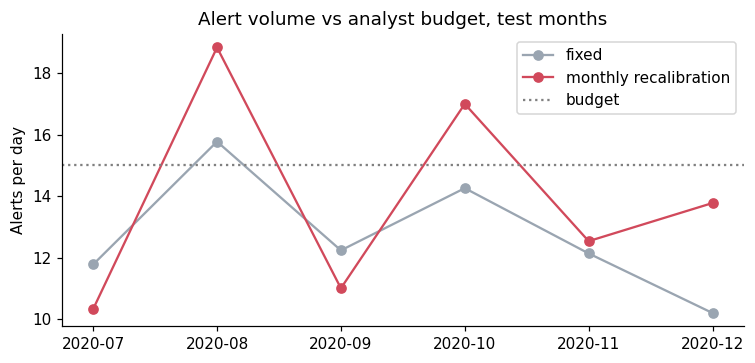

alerts/day                       recall                        \
method       fixed monthly recalibration  fixed monthly recalibration   
month                                                                   
2020-07     11.774                10.323  0.939                 0.926   
2020-08     15.774                18.839  0.971                 0.981   
2020-09     12.233                11.000  0.957                 0.942   
2020-10     14.258                17.000  0.969                 0.974   
2020-11     12.133                12.533  0.972                 0.972   
2020-12     10.194                13.774  0.940                 0.970   

        precision                        
method      fixed monthly recalibration  
month                                    
2020-07     0.762                 0.856  
2020-08     0.824                 0.697  
2020-09     0.722                 0.791  
2020-10     0.767                 0.647  
2020-11     0.772                 0.747  
2020-12     0.696                 0.532

In [23]:
scored = pd.concat([val.assign(p=p_val_b), test.assign(p=p_te_b)])[["ts", "date", "is_fraud", "p"]]
months = pd.period_range("2020-07", "2020-12", freq="M")
mon = []
for m in months:
    start = m.start_time
    hist = scored[(scored.ts >= start - pd.Timedelta(days=30)) & (scored.ts < start)]
    t_roll = threshold_for_budget(hist.p.values, hist.date.nunique(), BUDGET)
    cur = scored[(scored.ts >= start) & (scored.ts < m.end_time)]
    nd = cur.date.nunique()
    for label, t in [("fixed", t_b), ("monthly recalibration", t_roll)]:
        f = cur.p.values >= t
        mon.append({"month": str(m), "method": label, "alerts/day": f.sum() / nd,
                    "precision": precision_score(cur.is_fraud, f, zero_division=0), "recall": recall_score(cur.is_fraud, f)})
mon = pd.DataFrame(mon)

fig, ax = plt.subplots(figsize=(7, 3.4))
for label, col in [("fixed", C_STATIC), ("monthly recalibration", C_BEHAV)]:
    d = mon[mon.method == label]
    ax.plot(d.month, d["alerts/day"], "o-", color=col, label=label)
ax.axhline(BUDGET, ls=":", c="grey", label="budget")
ax.set(ylabel="Alerts per day", title="Alert volume vs analyst budget, test months"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "monitoring.png", bbox_inches="tight"); plt.show()
mon.pivot(index="month", columns="method", values=["alerts/day", "recall", "precision"]).round(3)

**Finding: monthly recalibration did not earn its place.** The fixed threshold already stayed close to budget (10–16 alerts/day) all six months. Recalibrating chased last month's noise: it pushed December to about 14/day and cut December precision from 0.70 to 0.53. The right call here is a fixed threshold plus a simple alert-volume check, with recalibration only if volume drifts outside a set range.

## 9. SHAP: why each alert fired

Global view on a random 30,000 test transactions plus all test frauds, then plain-English reason codes for individual alerts.

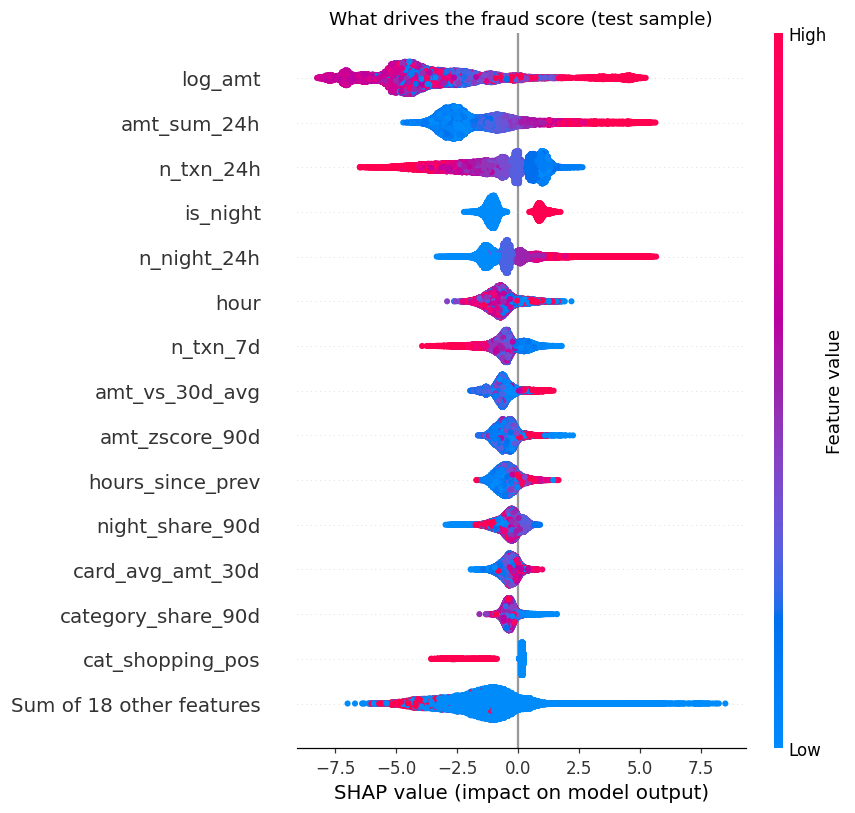

In [24]:
explainer = shap.TreeExplainer(model_b)
sample_idx = np.union1d(rng.choice(len(test), 30000, replace=False), np.flatnonzero(y_te == 1))
sv = explainer(test.iloc[sample_idx][feats_b])
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("What drives the fraud score (test sample)")
plt.tight_layout(); plt.savefig(FIG / "shap_beeswarm.png", bbox_inches="tight"); plt.show()

In [25]:
imp = pd.Series(np.abs(sv.values).mean(0), index=feats_b).sort_values(ascending=False)
behav_only = [f for f in feats_b if f not in STATIC]
print(f"Share of total |SHAP| from behavioural features: {imp[behav_only].sum() / imp.sum():.0%}")
print(imp.head(10).round(3).to_string())

Share of total |SHAP| from behavioural features: 48%
log_amt             3.990
amt_sum_24h         2.048
n_txn_24h           1.439
is_night            1.058
n_night_24h         0.932
hour                0.816
n_txn_7d            0.688
amt_vs_30d_avg      0.681
amt_zscore_90d      0.542
hours_since_prev    0.527


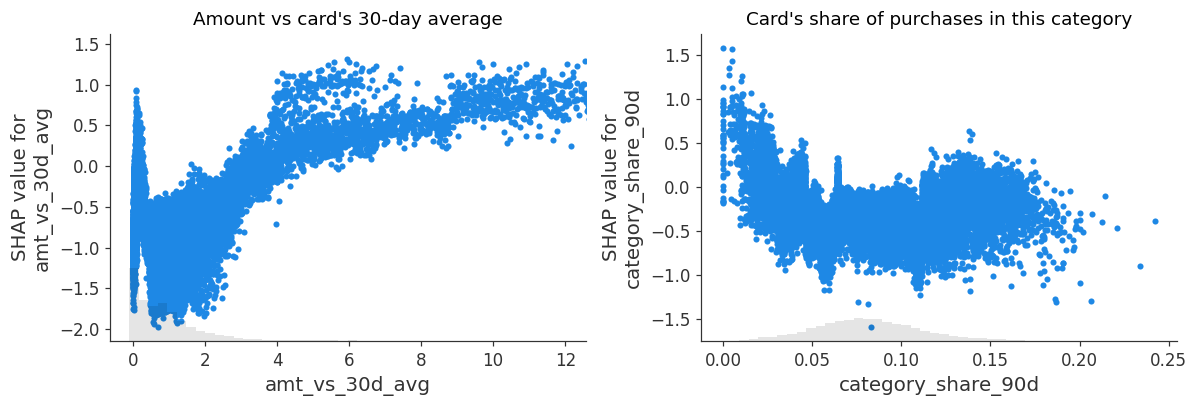

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
shap.plots.scatter(sv[:, "amt_vs_30d_avg"], ax=axes[0], show=False, xmax="percentile(99)")
shap.plots.scatter(sv[:, "category_share_90d"], ax=axes[1], show=False)
axes[0].set_title("Amount vs card's 30-day average"); axes[1].set_title("Card's share of purchases in this category")
plt.tight_layout(); plt.savefig(FIG / "shap_dependence.png", bbox_inches="tight"); plt.show()

### The analyst queue

Each alert gets its top three reasons in plain English. Below: the alerts from one typical day in the test period, highest score first. Several alerts often belong to the same card (one episode), so a real queue would group them by card.

In [27]:
alerts = test[flag_b].assign(score=p_te_b[flag_b])
per_day = alerts.date.value_counts()
day = per_day[per_day == per_day.median()].index.min() if (per_day == per_day.median()).any() else per_day.index[len(per_day) // 2]
q = alerts[alerts.date == day].sort_values("score", ascending=False)
q_sv = explainer(q[feats_b]).values
reasons = [top_reasons(q_sv[i], feats_b, q.iloc[i]) for i in range(len(q))]
queue = pd.DataFrame({
    "time": q.ts.dt.strftime("%H:%M"), "card": q.card_id, "alerts on card today": q.card_id.map(q.card_id.value_counts()),
    "amount $": q.amt.round(2), "category": q.category, "score": q.score.round(3),
    "reason 1": [r[0] if len(r) > 0 else "" for r in reasons],
    "reason 2": [r[1] if len(r) > 1 else "" for r in reasons],
    "reason 3": [r[2] if len(r) > 2 else "" for r in reasons],
    "actually fraud": q.is_fraud.map({1: "yes", 0: "no"}),
}).reset_index(drop=True)
queue.to_csv(OUT / "alert_queue_sample.csv", index=False)
print(f"Alert queue for {day:%Y-%m-%d}: {len(queue)} alerts on {queue.card.nunique()} cards, "
      f"{queue['actually fraud'].eq('yes').sum()} real frauds")
pd.set_option("display.max_colwidth", 80)
queue

Alert queue for 2020-07-18: 12 alerts on 4 cards, 11 real frauds


,time,card,alerts on card today,amount $,category,score,reason 1,reason 2,reason 3,actually fraud
0,23:01,9eaf881f2f41,6,1133.57,shopping_net,1.000,"Amount $1,134 is in a high-risk range","$3,179 already spent on this card in the past 24h",4 late-night transactions on this card in the past 24h,yes
1,22:31,9eaf881f2f41,6,822.11,shopping_pos,1.000,Amount $822 is in a high-risk range,"$2,357 already spent on this card in the past 24h",3 late-night transactions on this card in the past 24h,yes
2,22:09,9eaf881f2f41,6,958.05,shopping_net,1.000,Amount $958 is in a high-risk range,"$1,399 already spent on this card in the past 24h",7 transactions on this card in the past 7 days,yes
3,22:03,9eaf881f2f41,6,828.22,misc_net,1.000,Amount $828 is in a high-risk range,2 transactions on this card in the past 24h,6 transactions on this card in the past 7 days,yes
4,01:48,80923ef01336,3,335.98,grocery_pos,1.000,Category 'grocery_pos' carries higher fraud risk,Amount $336 is in a high-risk range,Amount $336 is 4.0x this card's 30-day average,yes
5,00:21,9eaf881f2f41,6,295.91,grocery_pos,0.999,Category 'grocery_pos' carries higher fraud risk,Amount $296 is in a high-risk range,Made late at night (22:00-04:00),yes
6,23:37,5ede0fe60e42,2,742.91,shopping_pos,0.998,Amount $743 is in a high-risk range,"$1,010 already spent on this card in the past 24h",2 transactions on this card in the past 24h,yes
7,18:43,9eaf881f2f41,6,275.16,grocery_pos,0.998,Category 'grocery_pos' carries higher fraud risk,Amount $275 is in a high-risk range,1 transaction on this card in the past 24h,yes
8,03:51,80923ef01336,3,1097.18,shopping_net,0.996,"Amount $1,097 is in a high-risk range",3 late-night transactions on this card in the past 24h,Made late at night (22:00-04:00),yes
9,15:42,80923ef01336,3,110.12,food_dining,0.983,"$1,526 already spent on this card in the past 24h",4 late-night transactions on this card in the past 24h,Category 'food_dining' carries higher fraud risk,yes


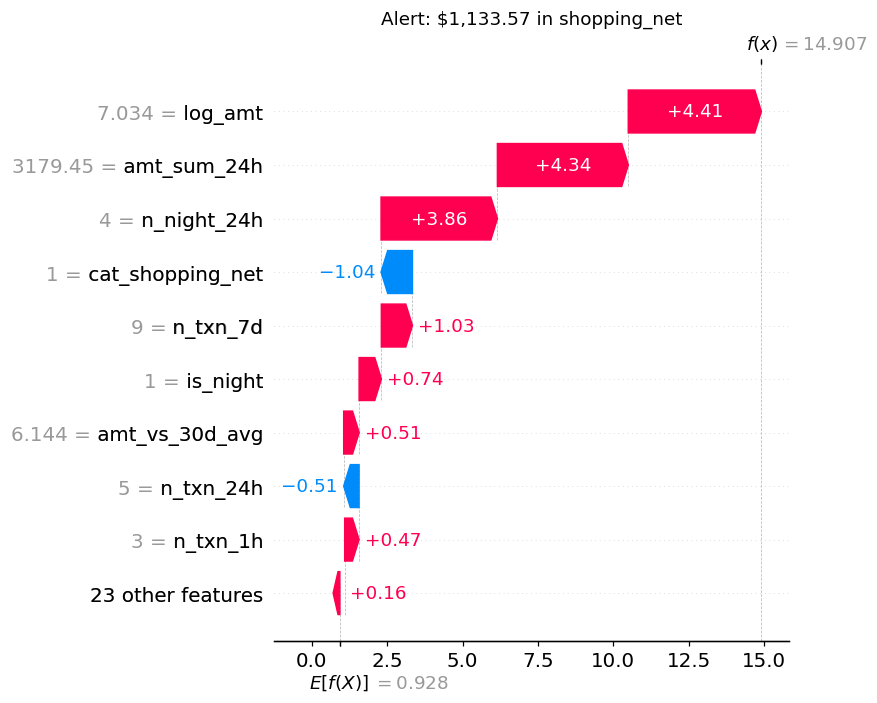

In [28]:
i = int(np.flatnonzero(q.is_fraud.values)[0])
shap.plots.waterfall(explainer(q[feats_b].iloc[[i]])[0], max_display=10, show=False)
plt.title(f"Alert: ${q.amt.iloc[i]:,.2f} in {q.category.iloc[i]}")
plt.tight_layout(); plt.savefig(FIG / "shap_waterfall_alert.png", bbox_inches="tight"); plt.show()

### What the false alarms look like

If analysts are going to trust the queue, it helps to know what wastes their time.

In [29]:
fa, tp = alerts[alerts.is_fraud == 0], alerts[alerts.is_fraud == 1]
pd.DataFrame({
    "real frauds": [len(tp), tp.amt.median(), tp.is_night.mean(), tp.amt_vs_30d_avg.median(), tp.n_txn_24h.median()],
    "false alarms": [len(fa), fa.amt.median(), fa.is_night.mean(), fa.amt_vs_30d_avg.median(), fa.n_txn_24h.median()],
}, index=["alerts", "median amount $", "share at night", "median amount vs 30d avg", "median txns in past 24h"]).round(2)

,real frauds,false alarms
alerts,1786.00,557.00
median amount $,364.28,643.81
share at night,0.85,0.66
median amount vs 30d avg,5.01,7.25
median txns in past 24h,4.00,3.00


In [30]:
cat_fa = pd.DataFrame({
    "share of false alarms": fa.category.value_counts(normalize=True),
    "fraud rate in train %": train.groupby("category").is_fraud.mean() * 100,
    "fraud rate in test %": test.groupby("category").is_fraud.mean() * 100,
}).sort_values("share of false alarms", ascending=False).head(6)
cat_fa.round(3)

,share of false alarms,fraud rate in train %,fraud rate in test %
category,,,
shopping_net,0.226,1.559,1.070
misc_net,0.158,1.268,0.859
shopping_pos,0.129,0.651,0.380
personal_care,0.072,0.229,0.175
misc_pos,0.068,0.289,0.193
food_dining,0.052,0.156,0.138


False alarms are large, unusual purchases (median about 7x the card's normal amount), in the categories fraud favours most, and more often during the day than real fraud. On paper they look like fraud. What would separate them is information this data does not have: device, whether the card was physically present, the customer confirming by text. That is the honest next step, not a bigger model.

## 10. How I would validate this before trusting it in production

1. **Shadow mode, 4–6 weeks:** score live transactions and log alerts, but don't act on them. Compare against what the current rules flag and what analysts confirm.
2. **Champion/challenger:** once in use, route a small random share of traffic to the old system, so the new one is always measured against a live comparison, not against its own past.
3. **Monitor weekly:** alert volume vs budget, precision from analyst decisions, score distribution drift (PSI), and fraud $ caught.
4. **Retrain on a schedule** that waits for chargeback labels to mature (typically 30–60 days), and re-run the leakage tests on every retrain.
5. **Keep feedback clean:** alerted transactions get blocked, so the model never sees what would have happened. Keeping a small unalerted random sample stops future training data from being shaped only by the model's own past decisions.

## 11. Limits

- **Synthetic data, with flaws.** The audit found fraud-only cards; there may be quirks it did not catch. Sparkov fraud also follows simple rules (large amounts, late-night hours, a few categories, bursts), so it is far easier than real fraud. The *methods* transfer: point-in-time features, leakage tests, data audits, budget-based thresholds, episode metrics. The exact scores do not.
- **One fraud episode per card.** Real cards can be hit more than once, and fraudsters change tactics once they notice what gets blocked.
- **Label delay.** Features never use past labels, but a real retraining schedule would also have to wait weeks for chargebacks to confirm fraud.
- **The 15/day budget is an assumption.** The budget curve shows the trade-off for other team sizes.